In [ ]:
pip install matplotlib

In [ ]:
import numpy as np

In [ ]:
from tomaz_aerodynamics import aerodynamic_forces, angle_of_attack, ground_velocity

In [ ]:
def f(t, x):
    return -x                      # the rule: how fast x changes

def rk4_step(f, t, x, h):
    k1 = f(t, x)                   # slope at start
    k2 = f(t + h/2, x + h/2 * k1)  # slope at middle (using k1)
    k3 = f(t + h/2, x + h/2 * k2)  # slope at middle again (using k2)
    k4 = f(t + h, x + h * k3)      # slope at end
    return x + h/6 * (k1 + 2*k2 + 2*k3 + k4)

for h in [0.1, 0.05, 0.025]:
    t, x = 0.0, 1.0
    while t < 1.0 - 1e-12:
        x = rk4_step(f, t, x, h)
        t += h
    print(h, abs(x - np.exp(-1)))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

g = 9.81

from tomaz_aerodynamics import aerodynamic_forces, angle_of_attack, ground_velocity

rho = 1.2                                    # air density (placeholder: check paper)
m, I = 60.0, 10.0                            # placeholders: check paper
theta, lam = np.radians(7), np.radians(25)   # posture (placeholders)
W = 0.0                                      # wind, positive = tail wind

def f(t, s):
    X, Y, U, beta, phi, omega = s
    alpha = angle_of_attack(phi, beta, theta)
    F = aerodynamic_forces(U, alpha, theta, lam,
                           air_density_kg_m3=rho, allow_extrapolation=True)
    L, D, M = F.lift_n, F.drag_n, F.moment_nm
    dX, dY = ground_velocity(U, beta, W)
    return np.array([
        dX,
        dY,
        -g * np.sin(beta) - D / m,
        (L / m - g * np.cos(beta)) / U,
        omega,
        M / I,
    ])

def rk4_step(f, t, x, h):
    k1 = f(t, x)
    k2 = f(t + h/2, x + h/2 * k1)
    k3 = f(t + h/2, x + h/2 * k2)
    k4 = f(t + h, x + h * k3)
    return x + h/6 * (k1 + 2*k2 + 2*k3 + k4)

U0, beta0 = 26.0, np.radians(-10)              # rough take-off values
s = np.array([0.0, 0.0, U0, beta0, 0.0, 0.0])
s0 = np.array([0.0, 0.0, 26.0, np.radians(-16.2), np.radians(20), 0.0])
h, t = 0.01, 0.0
path = [s]
while t < 3.0 - 1e-12:
    s = rk4_step(f, t, s, h)
    t += h
    path.append(s)
path = np.array(path)

# exact parabola for comparison
X_exact = U0 * np.cos(beta0) * t
Y_exact = U0 * np.sin(beta0) * t - g * t**2 / 2
print("error at t=3:", abs(path[-1, 0] - X_exact), abs(path[-1, 1] - Y_exact))

plt.plot(path[:, 0], path[:, 1])
plt.xlabel("X (m)"); plt.ylabel("Y (m)"); plt.axis("equal")
plt.show()

In [ ]:
H, slope = 3.0, np.radians(35)

def hill(X):
    return -H - np.tan(slope) * X        # hill height at position X

def simulate(h):
    s = np.array([0.0, 0.0, U0, beta0, 0.0, 0.0])
    t = 0.0
    while True:
        s_new = rk4_step(f, t, s, h)
        if s_new[1] <= hill(s_new[0]):   # crossed the hill in this step
            break
        s, t = s_new, t + h              # still above: accept the step

    # touchdown is somewhere between t and t + h
    lo, hi = 0.0, h
    for _ in range(50):
        mid = (lo + hi) / 2
        s_mid = rk4_step(f, t, s, mid)   # a shorter RK4 step from the last point above
        if s_mid[1] > hill(s_mid[0]):
            lo = mid                     # still above: touchdown is later
        else:
            hi = mid                     # below: touchdown is earlier
    return rk4_step(f, t, s, lo)[0]

    # touchdown is somewhere between t and t + h
    lo, hi = 0.0, h
    for _ in range(50):
        mid = (lo + hi) / 2
        s_mid = rk4_step(f, t, s, mid)   # a shorter RK4 step from the last point above
        if s_mid[1] > hill(s_mid[0]):
            lo = mid                     # still above: touchdown is later
        else:
            hi = mid                     # below: touchdown is earlier
    return rk4_step(f, t, s, lo)[0]

# exact landing for the no-air case (parabola meets straight line)
B = U0 * np.sin(beta0) + np.tan(slope) * U0 * np.cos(beta0)
t_land = (B + np.sqrt(B**2 + 2 * g * H)) / g
X_exact = U0 * np.cos(beta0) * t_land

for h in [0.1, 0.05, 0.025, 0.0125]:
    X = simulate(h)
    print(h, X, abs(X - X_exact))

In [ ]:
def simulate(h):
    s = np.array([0.0, 0.0, U0, beta0, 0.0, 0.0])
    t = 0.0
    while True:
        s_new = rk4_step(f, t, s, h)
        if s_new[1] <= hill(s_new[0]):   # crossed the hill in this step
            break
        s, t = s_new, t + h              # still above: accept the step

    # touchdown is somewhere between t and t + h
    lo, hi = 0.0, h
    for _ in range(50):
        mid = (lo + hi) / 2
        s_mid = rk4_step(f, t, s, mid)   # a shorter RK4 step from the last point above
        if s_mid[1] > hill(s_mid[0]):
            lo = mid                     # still above: touchdown is later
        else:
            hi = mid                     # below: touchdown is earlier
    return rk4_step(f, t, s, lo)[0]

In [ ]:
hs = [0.1, 0.05, 0.025, 0.0125]
errs = [abs(simulate(h) - X_exact) for h in hs]

plt.loglog(hs, errs, "o-", label="RK4 + landing search")
plt.loglog(hs, [errs[0] * (h / hs[0])**4 for h in hs], "--", label="slope 4")
plt.xlabel("time step h (s)"); plt.ylabel("landing error (m)")
plt.legend(); plt.grid(True, which="both"); plt.show()

0.1 151.26522106437875 nan
horizontal: 151.26522106437875   along the hill: 178.69965046856342
0.05 151.26487189813585 0.00034916624289849096
horizontal: 151.26487189813585   along the hill: 178.69930130232052
0.025 151.26486243103045 9.467105400062792e-06
horizontal: 151.26486243103045   along the hill: 178.69929183521512
0.0125 151.26486224971214 1.8131831325263192e-07
horizontal: 151.26486224971214   along the hill: 178.6992916538968


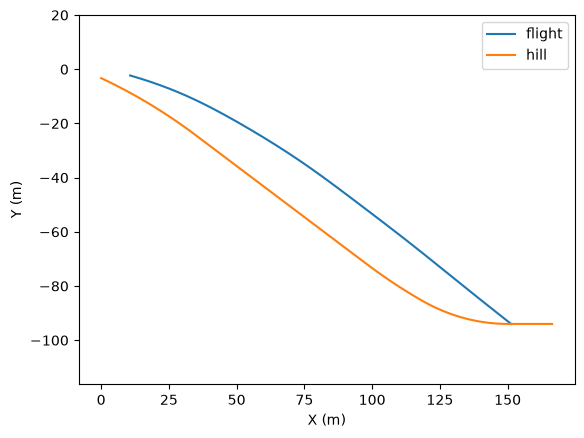

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from tomaz_aerodynamics import aerodynamic_forces, angle_of_attack, ground_velocity
AIR = True

g = 9.81
rho = 1.2                                    # air density (placeholder: check paper)
m, I = 60.0, 10.0                            # placeholders: check paper
theta, lam = np.radians(7), np.radians(25)   # posture (placeholders)
W = 0.0                                      # wind, positive = tail wind

def f(t, s):
    X, Y, U, beta, phi, omega = s
    alpha = angle_of_attack(phi, beta, theta)
    F = aerodynamic_forces(U, alpha, theta, lam,
                           air_density_kg_m3=rho, allow_extrapolation=True)
    L, D, M = F.lift_n, F.drag_n, F.moment_nm
    if not AIR:
        L, D, M = 0.0, 0.0, 0.0
    dX, dY = ground_velocity(U, beta, W)
    return np.array([
        dX,
        dY,
        -g * np.sin(beta) - D / m,
        (L / m - g * np.cos(beta)) / U,
        omega,
        M / I,
    ])

def rk4_step(f, t, x, h):
    k1 = f(t, x)
    k2 = f(t + h/2, x + h/2 * k1)
    k3 = f(t + h/2, x + h/2 * k2)
    k4 = f(t + h, x + h * k3)
    return x + h/6 * (k1 + 2*k2 + 2*k3 + k4)

# Approximate Okurayama profile: slope angle at each X, then integrate to heights
HX = np.linspace(0, 300, 3001)
hill_angle = np.interp(HX, [0, 35, 98, 118, 150], np.radians([25, 37, 37, 30, 0]))
HY = -3.3 - np.concatenate([[0], np.cumsum(np.tan(hill_angle[:-1]) * np.diff(HX))])

def hill(X):
    return np.interp(X, HX, HY)

def along_hill(X):
    """Distance measured along the hill surface, like in competitions."""
    S = np.concatenate([[0], np.cumsum(np.hypot(np.diff(HX), np.diff(HY)))])
    return np.interp(X, HX, S)

s0 = np.array([10.7, -2.3, 27.8,
               np.radians(-16.2), np.radians(20.0), np.radians(-20.0)])

def simulate(h):
    s, t = s0.copy(), 0.0
    path = [s]
    while True:
        s_new = rk4_step(f, t, s, h)
        if s_new[1] <= hill(s_new[0]):       # crossed the hill in this step
            break
        s, t = s_new, t + h
        path.append(s)

    lo, hi = 0.0, h                          # binary search inside the last step
    for _ in range(50):
        mid = (lo + hi) / 2
        s_mid = rk4_step(f, t, s, mid)
        if s_mid[1] > hill(s_mid[0]):
            lo = mid
        else:
            hi = mid
    s_land = rk4_step(f, t, s, lo)
    path.append(s_land)
    return s_land[0], np.array(path)

# convergence: compare each run with the previous one
prev = None
for h in [0.1, 0.05, 0.025, 0.0125]:
    X, path = simulate(h)
    diff = abs(X - prev) if prev is not None else float("nan")
    print(h, X, diff)
    print("horizontal:", X, "  along the hill:", along_hill(X))
    prev = X

# plot the flight and the hill
xs = np.linspace(0, path[-1, 0] * 1.1, 100)
plt.plot(path[:, 0], path[:, 1], label="flight")
plt.plot(xs, hill(xs), label="hill")
plt.xlabel("X (m)"); plt.ylabel("Y (m)"); plt.axis("equal")
plt.legend(); plt.show()

In [7]:
"""Midterm figures for the ski-jump solver.

Put this file next to tomaz_aerodynamics.py (and its CSV), then run:

    python make_plots.py

Figures are written to the folder figures/, and a summary table is printed.
The solver is the same as in the notebook; it is just wrapped in functions so
the sweeps can change the posture and wind without editing global variables.
"""

import pathlib

import matplotlib.pyplot as plt
import numpy as np

from tomaz_aerodynamics import (aerodynamic_forces, air_relative_velocity,
                                angle_of_attack, ground_velocity)

OUT = pathlib.Path("figures")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

# ---------------------------------------------------------------------------
#  Settings (same values as the notebook)
# ---------------------------------------------------------------------------
g = 9.81
rho = 1.2                     # air density (placeholder: check paper)
m, I = 60.0, 10.0             # placeholders: check paper
THETA = np.radians(7)         # forward lean, Seo et al. 2004
LAM = np.radians(25)          # ski opening, Seo et al. 2004
T0 = 0.4                      # the paper starts the simulation 0.4 s after take-off

# state at t = 0.4 s after take-off, Seo et al. (2004), Eqn. (12)
S0 = np.array([10.7, -2.3, 27.8,
               np.radians(-16.2), np.radians(20.0), np.radians(-20.0)])



def start_state(W=0.0):
    """The paper's state at 0.4 s, re-expressed relative to the air for wind W.

    The take-off happens on the ground, so the GROUND velocity at 0.4 s is the
    same whatever the wind (the first 0.4 s has no air forces). Only the
    velocity relative to the air changes: U_r and beta_r = ground velocity - wind.
    """
    vx = S0[2] * np.cos(S0[3])               # ground velocity with no wind
    vy = S0[2] * np.sin(S0[3])
    U_r, beta_r = air_relative_velocity(vx, vy, W)
    return np.array([S0[0], S0[1], U_r, beta_r, S0[4], S0[5]])


# distances from Seo et al. (2004), Table 1, fixed posture theta = 7, lambda = 25
PAPER_WIND = {-1.0: 135.0, 0.0: 131.0, 1.0: 127.0}


# ---------------------------------------------------------------------------
#  The model
# ---------------------------------------------------------------------------
def make_f(theta=THETA, lam=LAM, W=0.0, air=True):
    """Return the right-hand side f(t, s) for one posture and wind."""
    def f(t, s):
        X, Y, U, beta, phi, omega = s
        if air:
            alpha = angle_of_attack(phi, beta, theta)
            F = aerodynamic_forces(U, alpha, theta, lam, air_density_kg_m3=rho,
                                   allow_extrapolation=True)
            L, D, M = F.lift_n, F.drag_n, F.moment_nm
        else:
            L, D, M = 0.0, 0.0, 0.0
        dX, dY = ground_velocity(U, beta, W)
        return np.array([
            dX,
            dY,
            -g * np.sin(beta) - D / m,
            (L / m - g * np.cos(beta)) / U,
            omega,
            M / I,
        ])
    return f


def rk4_step(f, t, x, h):
    k1 = f(t, x)
    k2 = f(t + h/2, x + h/2 * k1)
    k3 = f(t + h/2, x + h/2 * k2)
    k4 = f(t + h, x + h * k3)
    return x + h/6 * (k1 + 2*k2 + 2*k3 + k4)


def simulate(f, s0, h, ground, t_max=20.0):
    """Fly until the jumper meets the ground; return times and states."""
    s, t = s0.copy(), 0.0
    ts, path = [t], [s]
    while True:
        s_new = rk4_step(f, t, s, h)
        if s_new[1] <= ground(s_new[0]):          # crossed the ground in this step
            break
        s, t = s_new, t + h
        if t > t_max:
            raise RuntimeError("no landing after %.0f s" % t_max)
        ts.append(t)
        path.append(s)

    lo, hi = 0.0, h                                # binary search inside the last step
    for _ in range(60):
        mid = (lo + hi) / 2
        s_mid = rk4_step(f, t, s, mid)
        if s_mid[1] > ground(s_mid[0]):
            lo = mid
        else:
            hi = mid
    ts.append(t + lo)
    path.append(rk4_step(f, t, s, lo))
    return np.array(ts), np.array(path)


# ---------------------------------------------------------------------------
#  The hills
# ---------------------------------------------------------------------------
# approximate Okurayama profile: slope angle at each X, integrated to heights
HX = np.linspace(0, 300, 3001)
HILL_ANGLE = np.interp(HX, [0, 35, 98, 118, 150], np.radians([25, 37, 37, 30, 0]))
HY = -3.3 - np.concatenate([[0], np.cumsum(np.tan(HILL_ANGLE[:-1]) * np.diff(HX))])
HS = np.concatenate([[0], np.cumsum(np.hypot(np.diff(HX), np.diff(HY)))])


def hill(X):
    return np.interp(X, HX, HY)


def along_hill(X):
    return np.interp(X, HX, HS)


# straight hill and vacuum start, used only for validation (exact answer known)
V_H, V_SLOPE = 3.0, np.radians(35)
V_U0, V_BETA0 = 26.0, np.radians(-10)
V_S0 = np.array([0.0, 0.0, V_U0, V_BETA0, 0.0, 0.0])


def straight_hill(X):
    return -V_H - np.tan(V_SLOPE) * X


def vacuum_exact(t):
    """Exact parabola for the vacuum start."""
    return (V_U0 * np.cos(V_BETA0) * t,
            V_U0 * np.sin(V_BETA0) * t - g * t**2 / 2)


def vacuum_landing_exact():
    B = V_U0 * np.sin(V_BETA0) + np.tan(V_SLOPE) * V_U0 * np.cos(V_BETA0)
    t_land = (B + np.sqrt(B**2 + 2 * g * V_H)) / g
    return t_land, V_U0 * np.cos(V_BETA0) * t_land


# ---------------------------------------------------------------------------
#  Quantities along a flight
# ---------------------------------------------------------------------------
def diagnostics(path, theta=THETA, lam=LAM):
    """Angle of attack, areas and forces at every recorded state."""
    out = {k: [] for k in ("alpha", "SD", "SL", "Q", "D", "L", "M", "inside")}
    for X, Y, U, beta, phi, omega in path:
        alpha = angle_of_attack(phi, beta, theta)
        F = aerodynamic_forces(U, alpha, theta, lam, air_density_kg_m3=rho,
                               allow_extrapolation=True)
        out["alpha"].append(alpha)
        out["SD"].append(F.properties.drag_area_m2)
        out["SL"].append(F.properties.lift_area_m2)
        out["Q"].append(F.properties.moment_volume_m3)
        out["D"].append(F.drag_n)
        out["L"].append(F.lift_n)
        out["M"].append(F.moment_nm)
        out["inside"].append(F.properties.within_angle_domain)
    return {k: np.array(v) for k, v in out.items()}


def landing(theta=THETA, lam=LAM, W=0.0, h=0.01):
    """Landing X for one posture and wind, or nan if there is no landing."""
    try:
        _, path = simulate(make_f(theta, lam, W), start_state(W), h, hill)
        return path[-1, 0]
    except RuntimeError:
        return np.nan


# ---------------------------------------------------------------------------
#  Figure 1: convergence of the landing point (vacuum, exact answer known)
# ---------------------------------------------------------------------------
def fig_convergence():
    f_vac = make_f(air=False)
    _, X_exact = vacuum_landing_exact()
    hs = np.array([0.2, 0.1, 0.05, 0.025, 0.0125, 0.00625])
    errs = np.array([abs(simulate(f_vac, V_S0, h, straight_hill)[1][-1, 0] - X_exact)
                     for h in hs])
    p, logc = np.polyfit(np.log(hs), np.log(errs), 1)

    fig, ax = plt.subplots(figsize=(6.4, 4.6))
    ax.loglog(hs, errs, "o-", lw=2, label=f"RK4 + landing search (fitted slope {p:.2f})")
    ax.loglog(hs, errs[0] * (hs / hs[0])**4, "--", color="gray", label="reference slope 4")
    ax.loglog(hs, errs[0] * (hs / hs[0])**1, ":", color="gray", label="reference slope 1 (Euler)")
    for h, e, e_next in zip(hs[:-1], errs[:-1], errs[1:]):
        ax.annotate(f"÷{e / e_next:.1f}", (h, e), textcoords="offset points",
                    xytext=(6, -12), fontsize=8)
    ax.set_xlabel("time step $h$ (s)")
    ax.set_ylabel(r"landing error $|X_h - X_{\mathrm{exact}}|$ (m)")
    ax.set_title(r"Convergence: error $\propto h^p$, RK4 expects $p = 4$")
    ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT / "fig1_convergence.png")
    plt.close(fig)
    return p, hs, errs


# ---------------------------------------------------------------------------
#  Figure 2: vacuum flight against the exact parabola
# ---------------------------------------------------------------------------
def fig_validation():
    f_vac = make_f(air=False)
    ts, path = simulate(f_vac, V_S0, 0.05, straight_hill)
    Xe, Ye = vacuum_exact(ts)
    err = np.hypot(path[:, 0] - Xe, path[:, 1] - Ye)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
    xs = np.linspace(0, path[-1, 0] * 1.1, 50)
    a1.plot(xs, straight_hill(xs), color="gray", lw=2, label="straight test hill (35°)")
    a1.plot(Xe, Ye, "-", lw=6, alpha=0.3, label="exact parabola")
    a1.plot(path[::4, 0], path[::4, 1], "o", ms=4, label="RK4, $h$ = 0.05 s")
    a1.set_xlabel("$X$ (m)"); a1.set_ylabel("$Y$ (m)"); a1.axis("equal")
    a1.set_title(r"No air: $X = U_0\cos\beta_0\,t$,  $Y = U_0\sin\beta_0\,t - \frac{1}{2}gt^2$")
    a1.legend(fontsize=8)

    a2.semilogy(ts[1:], err[1:], lw=2)
    a2.set_xlabel("time $t$ (s)")
    a2.set_ylabel("distance from exact position (m)")
    a2.set_title("Position error along the flight")
    fig.tight_layout()
    fig.savefig(OUT / "fig2_validation.png")
    plt.close(fig)
    return err.max()


# ---------------------------------------------------------------------------
#  Figures 3 to 5: the reference jump (theta = 7, lambda = 25, no wind)
# ---------------------------------------------------------------------------
def fig_flight(ts, path, d):
    X_land = path[-1, 0]
    fig, ax = plt.subplots(figsize=(11, 5))
    xs = np.linspace(0, max(170, X_land * 1.1), 400)
    ax.fill_between(xs, hill(xs), hill(xs).min() - 10, color="0.85", label="hill (approximate)")
    ax.plot(path[:, 0], path[:, 1], lw=2, label="flight (centre of gravity)")

    # posture every 0.5 s: skis at angle phi - theta, body at angle phi (drawn 3x size)
    scale = 3.0
    every = max(1, int(round(0.5 / (ts[1] - ts[0]))))
    for X, Y, U, beta, phi, omega in path[::every]:
        ski = phi - THETA
        ax.plot([X - 1.3 * scale * np.cos(ski), X + 1.3 * scale * np.cos(ski)],
                [Y - 1.3 * scale * np.sin(ski), Y + 1.3 * scale * np.sin(ski)],
                color="#1D9E75", lw=1.6)
        ax.plot([X, X + 0.9 * scale * np.cos(phi)], [Y, Y + 0.9 * scale * np.sin(phi)],
                color="#7F77DD", lw=2.2)
    ax.plot([], [], color="#1D9E75", label=r"skis (angle $\varphi - \theta$), every 0.5 s")
    ax.plot([], [], color="#7F77DD", label=r"body (angle $\varphi$), 3× size")

    ax.plot(X_land, path[-1, 1], "o", color="#D85A30", ms=8)
    t_flight = ts[-1] + T0
    U_land = path[-1, 2]
    ax.annotate(f"landing\n$X$ = {X_land:.1f} m horizontal\n"
                f"{along_hill(X_land):.1f} m along the hill\n"
                f"flight time {t_flight:.2f} s\n"
                f"speed {U_land:.1f} m/s ({U_land * 3.6:.0f} km/h)",
                (X_land, path[-1, 1]), xytext=(-170, -10), textcoords="offset points",
                fontsize=9, arrowprops=dict(arrowstyle="->"),
                bbox=dict(boxstyle="round", fc="white", ec="0.7"))
    ax.set_xlabel("$X$ (m)"); ax.set_ylabel("$Y$ (m)")
    ax.set_xlim(0, xs[-1]); ax.set_aspect("equal", adjustable="box")
    ax.set_title(r"Reference jump: $\theta = 7°$, $\lambda = 25°$, no wind")
    ax.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT / "fig3_flight.png")
    plt.close(fig)


def fig_angles(ts, path, d):
    t = ts + T0
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True,
                                 gridspec_kw={"height_ratios": [2.2, 1]})
    a1.axhspan(0, 50, color="#BA7517", alpha=0.07, label=r"measured range of $\alpha$ (0–50°)")
    a1.plot(t, np.degrees(d["alpha"]), lw=2, color="#BA7517", label=r"angle of attack $\alpha$")
    a1.plot(t, np.degrees(path[:, 4]), lw=2, color="#7F77DD", label=r"body angle $\varphi$")
    a1.plot(t, np.degrees(path[:, 3]), lw=2, color="#378ADD", label=r"flight-path angle $\beta_r$")
    a1.axhline(24, ls="--", color="#BA7517", lw=1)
    a1.text(t[-1], 25, "trim ≈ 24° (paper)", ha="right", va="bottom", fontsize=8, color="#BA7517")
    a1.axhline(np.degrees(THETA), ls=":", color="gray", lw=1)
    a1.text(t[-1], np.degrees(THETA) + 1, r"$\theta$ = 7°", ha="right", fontsize=8, color="gray")
    a1.set_ylabel("angle (°)")
    a1.set_title(r"Angles during the flight, $\alpha = \varphi - \beta_r - \theta$")
    a1.legend(loc="lower left", fontsize=8, ncol=2)

    a2.plot(t, np.degrees(path[:, 5]), lw=2, color="0.3")
    a2.axhline(0, color="gray", lw=0.8)
    a2.set_ylabel(r"$\omega$ (°/s)")
    a2.set_xlabel("time since take-off (s)")
    a2.set_title(r"Angular velocity $\omega = \dot\varphi$ (positive = nose up)")
    fig.tight_layout()
    fig.savefig(OUT / "fig4_angles.png")
    plt.close(fig)


def fig_forces(ts, path, d):
    t = ts + T0
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    a1.plot(t, d["SL"], lw=2, color="#378ADD", label=r"lift area $S_L$")
    a1.plot(t, d["SD"], lw=2, color="#D85A30", label=r"drag area $S_D$")
    a1.set_ylabel(r"area (m$^2$)")
    b1 = a1.twinx()
    b1.plot(t, d["Q"], lw=1.5, ls="--", color="0.3", label=r"moment volume $Q$")
    b1.axhline(0, color="gray", lw=0.6)
    b1.set_ylabel(r"$Q$ (m$^3$)")
    b1.grid(False)
    lines = a1.get_legend_handles_labels()
    lines2 = b1.get_legend_handles_labels()
    a1.legend(lines[0] + lines2[0], lines[1] + lines2[1], fontsize=8, loc="upper right")
    a1.set_title(r"Aerodynamic coefficients: force $= \frac{1}{2}\rho U_r^2 \times$ area")

    a2.plot(t, d["L"], lw=2, color="#378ADD", label="lift $L$")
    a2.plot(t, d["D"], lw=2, color="#D85A30", label="drag $D$")
    a2.axhline(m * g, ls="--", color="0.3", lw=1.2, label=f"weight $mg$ = {m * g:.0f} N")
    a2.set_ylabel("force (N)")
    b2 = a2.twinx()
    b2.plot(t, path[:, 2], lw=1.5, ls=":", color="#1D9E75", label="air speed $U_r$")
    b2.set_ylabel(r"$U_r$ (m/s)")
    b2.grid(False)
    lines = a2.get_legend_handles_labels()
    lines2 = b2.get_legend_handles_labels()
    a2.legend(lines[0] + lines2[0], lines[1] + lines2[1], fontsize=8, loc="center left")
    a2.set_xlabel("time since take-off (s)")
    a2.set_title(rf"Forces (mean $L/D$ = {np.mean(d['L'] / d['D']):.2f})")
    fig.tight_layout()
    fig.savefig(OUT / "fig5_forces.png")
    plt.close(fig)


# ---------------------------------------------------------------------------
#  Figures 6 and 7: sweeps
# ---------------------------------------------------------------------------
def fig_wind():
    winds = np.arange(-3.0, 3.01, 0.5)
    dist = np.array([landing(W=w) for w in winds])
    fig, ax = plt.subplots(figsize=(7, 4.6))
    ax.plot(winds, dist, "o-", lw=2, label=r"our model ($\theta$ = 7°, $\lambda$ = 25°)")
    ax.plot(list(PAPER_WIND), list(PAPER_WIND.values()), "s", ms=8, color="#D85A30",
            label="Seo et al. (2004), Table 1")
    ax.axvline(0, color="gray", lw=0.8)
    ax.text(-2.9, ax.get_ylim()[1], "head wind", va="top", fontsize=9)
    ax.text(2.9, ax.get_ylim()[1], "tail wind", va="top", ha="right", fontsize=9)
    ax.set_xlabel(r"wind speed $U_w$ (m/s), positive = tail wind")
    ax.set_ylabel("horizontal landing distance $X$ (m)")
    ax.set_title(r"Effect of wind: $U_r^2$ grows in a head wind, so lift grows")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT / "fig6_wind.png")
    plt.close(fig)
    return winds, dist


def fig_posture():
    lams = np.arange(0, 25.01, 2.5)
    thetas = np.arange(2, 16.01, 1.0)
    d_lam = np.array([landing(lam=np.radians(v)) for v in lams])
    d_th = np.array([landing(theta=np.radians(v)) for v in thetas])

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
    a1.plot(lams, d_lam, "o-", lw=2)
    a1.set_xlabel(r"ski opening $\lambda$ (°)")
    a1.set_ylabel("landing distance $X$ (m)")
    a1.set_title(r"Wider V, more lift ($\theta$ = 7°)")
    a2.plot(thetas, d_th, "o-", lw=2, color="#7F77DD")
    if np.isfinite(d_th).any():
        best = np.nanargmax(d_th)
        a2.plot(thetas[best], d_th[best], "*", ms=14, color="#D85A30",
                label=rf"best $\theta$ = {thetas[best]:.0f}°")
        a2.legend(fontsize=8)
    a2.set_xlabel(r"forward lean $\theta$ (°)")
    a2.set_title(r"Forward lean ($\lambda$ = 25°); paper: best ≈ 7°")
    fig.tight_layout()
    fig.savefig(OUT / "fig7_posture.png")
    plt.close(fig)
    return lams, d_lam, thetas, d_th


# ---------------------------------------------------------------------------
if __name__ == "__main__":
    p, hs, errs = fig_convergence()
    max_err = fig_validation()

    ts, path = simulate(make_f(), S0, 0.01, hill)
    d = diagnostics(path)
    fig_flight(ts, path, d)
    fig_angles(ts, path, d)
    fig_forces(ts, path, d)
    winds, dist = fig_wind()
    lams, d_lam, thetas, d_th = fig_posture()

    print("\n=== Convergence (vacuum, exact landing known) ===")
    for h, e in zip(hs, errs):
        print(f"  h = {h:<8} error = {e:.3e} m")
    print(f"  fitted order p = {p:.2f}  (RK4: 4)")
    print(f"\n=== Validation === max position error vs parabola: {max_err:.2e} m")

    print("\n=== Reference jump (theta 7, lambda 25, no wind) ===")
    print(f"  landing X          {path[-1, 0]:.1f} m  (paper: 131 m)")
    print(f"  along the hill     {along_hill(path[-1, 0]):.1f} m")
    print(f"  flight time        {ts[-1] + T0:.2f} s since take-off")
    print(f"  landing speed      {path[-1, 2]:.1f} m/s")
    print(f"  alpha range        {np.degrees(d['alpha']).min():.1f} to "
          f"{np.degrees(d['alpha']).max():.1f} deg, mean {np.degrees(d['alpha']).mean():.1f}")
    print(f"  inside measured angle range: {100 * d['inside'].mean():.0f}% of the flight")

    print("\n=== Wind ===")
    for w, x in zip(winds, dist):
        ref = PAPER_WIND.get(float(w))
        print(f"  W = {w:+.1f} m/s  ->  {x:6.1f} m" + (f"   (paper {ref:.0f} m)" if ref else ""))

    print("\nFigures written to", OUT.resolve())


=== Convergence (vacuum, exact landing known) ===
  h = 0.2      error = 6.480e-05 m
  h = 0.1      error = 4.046e-06 m
  h = 0.05     error = 2.525e-07 m
  h = 0.025    error = 1.577e-08 m
  h = 0.0125   error = 9.853e-10 m
  h = 0.00625  error = 6.133e-11 m
  fitted order p = 4.00  (RK4: 4)

=== Validation === max position error vs parabola: 1.16e-07 m

=== Reference jump (theta 7, lambda 25, no wind) ===
  landing X          151.3 m  (paper: 131 m)
  along the hill     178.7 m
  flight time        5.72 s since take-off
  landing speed      36.4 m/s
  alpha range        14.7 to 29.2 deg, mean 21.7
  inside measured angle range: 100% of the flight

=== Wind ===
  W = -3.0 m/s  ->   153.9 m
  W = -2.5 m/s  ->   153.6 m
  W = -2.0 m/s  ->   153.2 m
  W = -1.5 m/s  ->   152.7 m
  W = -1.0 m/s  ->   152.3 m   (paper 135 m)
  W = -0.5 m/s  ->   151.8 m
  W = +0.0 m/s  ->   151.3 m   (paper 131 m)
  W = +0.5 m/s  ->   150.7 m
  W = +1.0 m/s  ->   150.2 m   (paper 127 m)
  W = +1.5 m/s  -> 